# Explainable AI (SHAP)
Employee Attrition Risk Analyzer

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import shap
from sklearn.model_selection import train_test_split

data = pd.read_csv("../data/processed/model_ready_data.csv")
X = data.drop(columns=["Attrition"])
y = data["Attrition"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

best_model = joblib.load("../models/best_model.pkl")
scaler = best_model.named_steps["scaler"]
clf = best_model.named_steps["clf"]

X_train_s = pd.DataFrame(scaler.transform(X_train), columns=X.columns)
X_all_s = pd.DataFrame(scaler.transform(X), columns=X.columns)
print("Model:", type(clf).__name__, "| Features:", X.shape[1])


c:\Users\yash gupta\AppData\Local\Python\pythoncore-3.13-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model: LogisticRegression | Features: 44


In [2]:
masker = shap.maskers.Independent(X_train_s, max_samples=len(X_train_s))
explainer = shap.LinearExplainer(clf, masker)
shap_values = explainer(X_all_s)
print(shap_values.values.shape)

(1470, 44)


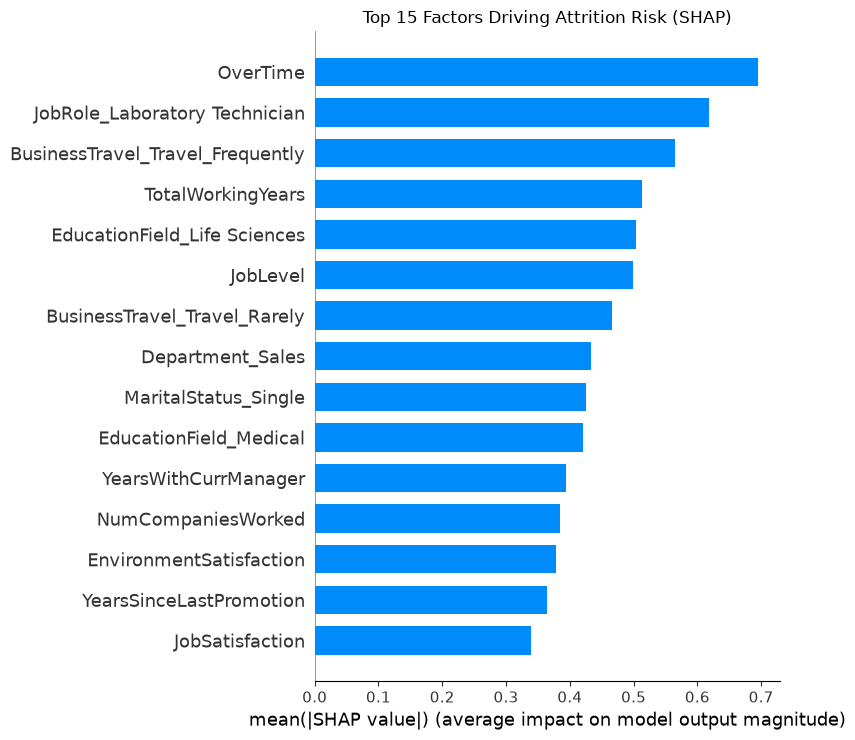

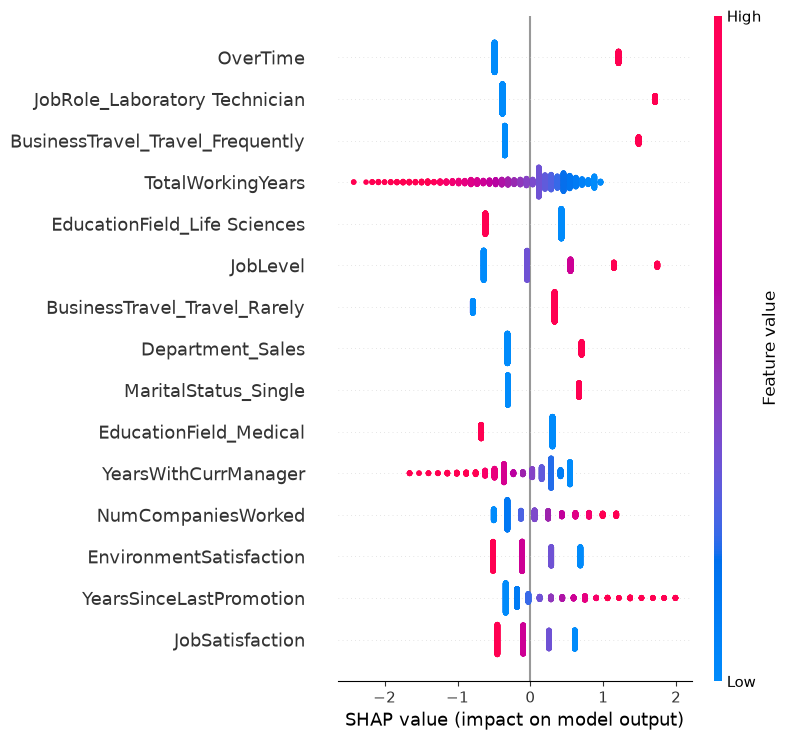

In [3]:
plt.figure()
shap.summary_plot(shap_values.values, X_all_s, plot_type="bar", max_display=15, show=False)
plt.title("Top 15 Factors Driving Attrition Risk (SHAP)")
plt.tight_layout()
plt.savefig("../outputs/charts/05_shap_global_importance.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure()
shap.summary_plot(shap_values.values, X_all_s, max_display=15, show=False)
plt.tight_layout()
plt.savefig("../outputs/charts/05_shap_beeswarm.png", dpi=300, bbox_inches="tight")
plt.show()

In [4]:
def clean_name(f):
    return f.replace("_", " = ", 1) if "_" in f else f

vals = shap_values.values
feats = np.array(X.columns)

reasons = []
for i in range(len(vals)):
    idx = np.argsort(-vals[i])[:3]
    idx = [j for j in idx if vals[i][j] > 0]
    reasons.append([clean_name(feats[j]) for j in idx])

risk = pd.read_csv("../data/processed/risk_scores.csv")
risk["Reason1"] = [r[0] if len(r) > 0 else "" for r in reasons]
risk["Reason2"] = [r[1] if len(r) > 1 else "" for r in reasons]
risk["Reason3"] = [r[2] if len(r) > 2 else "" for r in reasons]
risk["Top_Reasons"] = [" | ".join(r) for r in reasons]

risk.to_csv("../data/processed/risk_with_reasons.csv", index=False)
pd.DataFrame(vals, columns=X.columns).to_csv("../data/processed/shap_values.csv", index=False)

risk[["EmployeeNumber", "Department", "RiskScore", "RiskLevel", "Top_Reasons"]].head(10)

,EmployeeNumber,Department,RiskScore,RiskLevel,Top_Reasons
0,1,Sales,90.6,High,OverTime | NumCompaniesWorked | Department = S...
1,2,Research & Development,10.7,Low,BusinessTravel = Travel_Frequently | JobRole =...
2,4,Research & Development,85.1,High,JobRole = Laboratory Technician | OverTime | M...
3,5,Research & Development,52.8,Medium,BusinessTravel = Travel_Frequently | OverTime ...
4,7,Research & Development,60.1,High,JobRole = Laboratory Technician | NumCompanies...
5,8,Research & Development,28.4,Low,JobRole = Laboratory Technician | BusinessTrav...
6,10,Research & Development,55.9,Medium,JobRole = Laboratory Technician | OverTime | J...
7,11,Research & Development,20.4,Low,JobRole = Laboratory Technician | TotalWorking...
8,12,Research & Development,30.5,Medium,BusinessTravel = Travel_Frequently | MaritalSt...
9,13,Research & Development,22.6,Low,YearsSinceLastPromotion | DistanceFromHome | N...


Employee: 1 | Risk Score: 90.6 | Reasons: OverTime | NumCompaniesWorked | Department = Sales


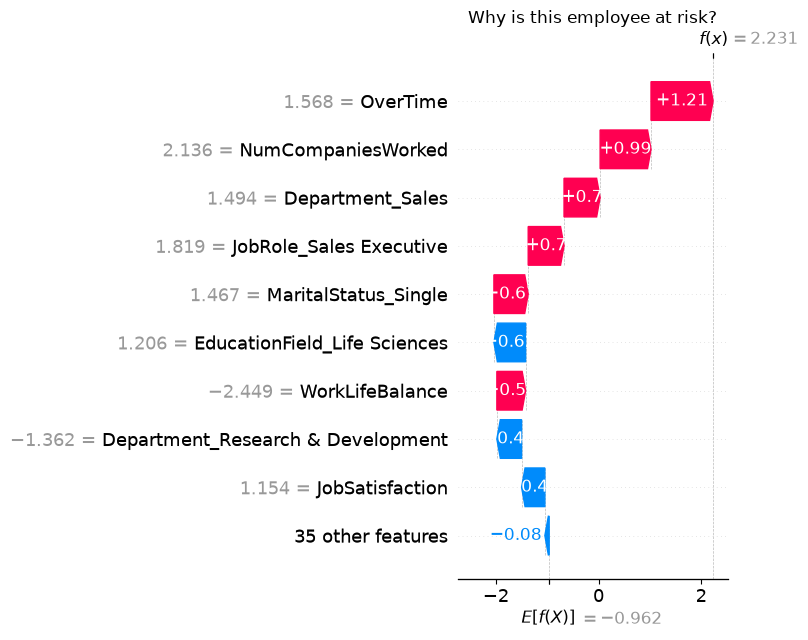

In [5]:
i = 0
print("Employee:", risk.loc[i, "EmployeeNumber"],
      "| Risk Score:", risk.loc[i, "RiskScore"],
      "| Reasons:", risk.loc[i, "Top_Reasons"])

shap.plots.waterfall(shap_values[i], max_display=10, show=False)
plt.title("Why is this employee at risk?")
plt.tight_layout()
plt.savefig("../outputs/charts/05_shap_waterfall_employee.png", dpi=300, bbox_inches="tight")
plt.show()

In [6]:
high = risk[risk["RiskLevel"] == "High"]
print(high["Reason1"].value_counts().head(8))

Reason1
JobRole = Laboratory Technician       96
OverTime                              86
JobRole = Sales Representative        53
BusinessTravel = Travel_Frequently    41
YearsSinceLastPromotion               21
JobRole = Human Resources             20
Department = Sales                    11
NumCompaniesWorked                    11
Name: count, dtype: int64


In [7]:
actionable = ["OverTime", "BusinessTravel_Travel_Frequently", "YearsSinceLastPromotion",
              "JobSatisfaction", "EnvironmentSatisfaction", "WorkLifeBalance",
              "MonthlyIncome", "StockOptionLevel", "DistanceFromHome",
              "TrainingTimesLastYear", "YearsWithCurrManager", "YearsInCurrentRole",
              "JobInvolvement", "PercentSalaryHike", "RelationshipSatisfaction"]
actionable = [c for c in actionable if c in X.columns]
act_idx = [list(X.columns).index(c) for c in actionable]

def top_actionable(i, k=3):
    v = vals[i][act_idx]
    order = np.argsort(-v)[:k]
    return [actionable[j] for j in order if v[j] > 0]

act = [top_actionable(i) for i in range(len(vals))]
risk["Action1"] = [r[0] if len(r) > 0 else "" for r in act]
risk["Action2"] = [r[1] if len(r) > 1 else "" for r in act]
risk["Action3"] = [r[2] if len(r) > 2 else "" for r in act]
risk["Top_Actionable_Reasons"] = [" | ".join(r) for r in act]

low = risk["RiskLevel"] == "Low"
risk.loc[low, ["Top_Reasons", "Top_Actionable_Reasons"]] = "No major risk factors"

risk.to_csv("../data/processed/risk_with_reasons.csv", index=False)

print(risk.loc[~low, "Action1"].value_counts().head(8))

Action1
OverTime                            230
BusinessTravel_Travel_Frequently    171
EnvironmentSatisfaction              73
YearsSinceLastPromotion              60
YearsWithCurrManager                 47
JobSatisfaction                      42
DistanceFromHome                     33
JobInvolvement                       29
Name: count, dtype: int64
